Initializing and scaling data

(100, 1) (100,)


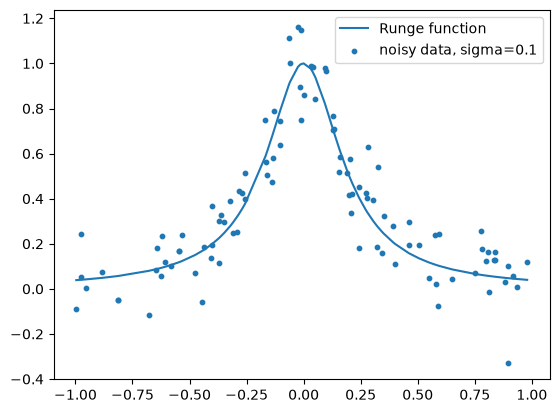

In [2]:
# The data of project 1, as a starting point for part b)
import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp  
from sklearn.model_selection import train_test_split
from neural_network_functions import *
import seaborn as sns

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)

X_test = (Xtest - Xtrain.mean(axis=0)) / Xtrain.std(axis=0)  # Standardize the input features
y_test = (ytest - ytrain.mean()) / ytrain.std()  # Standardize the target variable

X_scaled = (X - Xtrain.mean(axis=0)) / Xtrain.std(axis=0)

X_train = (Xtrain - Xtrain.mean(axis=0)) / Xtrain.std(axis=0)  # Standardize the input features
y_train = (ytrain - ytrain.mean()) / ytrain.std()  # Standardize the target variable


Yrunge = runge(X.flatten())
Yrunge_scaled = (Yrunge - Yrunge.mean()) / Yrunge.std()  # Standardize the Runge function values





One hidden layer

In [13]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

input_size = 1
layer_output_sizes = [50, 1]
np.random.seed(2026)  # Set the random seed for reproducibility
layers_one_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_one_hidden_layer = train_sgd_adam(
    Xtrain = X_train,
    Ytrain = y_train.reshape(-1, 1),
    layers = layers_one_hidden_layer,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


Two hidden layers

In [14]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

input_size = 1
layer_output_sizes = [50,50, 1]
np.random.seed(2026)  # Set the random seed for reproducibility
layers_two_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_two_hidden_layer = train_sgd_adam(
    Xtrain = X_train,
    Ytrain = y_train.reshape(-1, 1),
    layers = layers_two_hidden_layer,
    activation_funcs = [sigmoid, sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


One and two hidden layers vs true function

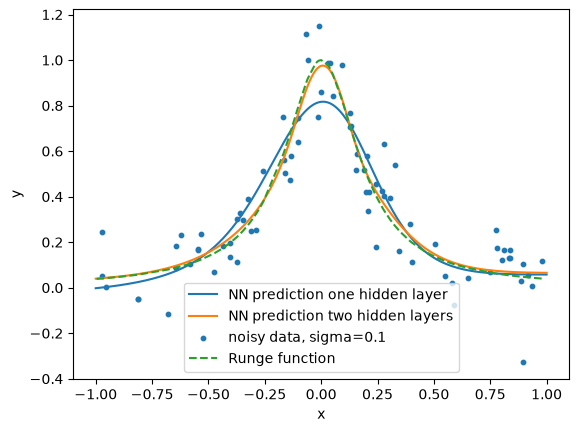

In [23]:
y_pred_one_hidden_layers = feed_forward(X_test, layers_one_hidden_layer, [sigmoid, lambda z: z])
y_pred_two_hidden_layers = feed_forward(X_test, layers_two_hidden_layer, [sigmoid, sigmoid, lambda z: z])
sort_idx = np.argsort(X_test.flatten()) #<- Chatgpt la til fix

y_one_hidden_unscaled = y_pred_one_hidden_layers.flatten()*ytrain.std()+ytrain.mean()
y_two_hidden_unscaled = y_pred_two_hidden_layers.flatten()*ytrain.std()+ytrain.mean()

#Skrevet av UiOGPT:---------------
X_plot = np.linspace(-1.0, 1.0, 500).reshape(-1, 1)
X_plot_scaled = (X_plot - Xtrain.mean(axis=0)) / Xtrain.std(axis=0)

y_one_hidden_plot = feed_forward(
    X_plot_scaled,
    layers_one_hidden_layer,
    [sigmoid, lambda z: z]
).flatten() * ytrain.std() + ytrain.mean()

y_two_hidden_plot = feed_forward(
    X_plot_scaled,
    layers_two_hidden_layer,
    [sigmoid, sigmoid, lambda z: z]
).flatten() * ytrain.std() + ytrain.mean()
#-----------------------------


plt.plot(X_plot, y_one_hidden_plot, label="NN prediction one hidden layer")
plt.plot(X_plot, y_two_hidden_plot, label="NN prediction two hidden layers")

plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.plot(X, Yrunge, label="Runge function", linestyle="--")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [24]:


MSE_one_hidden = np.mean((y_one_hidden_unscaled - ytest)**2)
print(f"MSE for one hidden layer: {MSE_one_hidden}")

MSE_two_hidden = np.mean((y_two_hidden_unscaled - ytest)**2)
print(f"MSE for two hidden layers: {MSE_two_hidden}")

MSE for one hidden layer: 0.01892671547830105
MSE for two hidden layers: 0.013736876659095287


One hidden layer for Adam, plain descent, and RMSprop 

In [2]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

input_size = 1
layer_output_sizes = [50, 1]
layers_adam = create_layers(input_size, layer_output_sizes)
layers_adam = train_sgd_adam(
    Xtrain = X_train,
    Ytrain = y_train.reshape(-1, 1),
    layers = layers_adam,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)

layers_plain = create_layers(input_size, layer_output_sizes)
layers_plain = train_sgd_plain(
    Xtrain = X_train,
    Ytrain = y_train.reshape(-1, 1),
    layers = layers_plain,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)

layers_RMSprop = create_layers(input_size, layer_output_sizes)
layers_RMSprop = train_sgd_RMSprop(
    Xtrain = X_train,
    Ytrain = y_train.reshape(-1, 1),
    layers = layers_RMSprop,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)

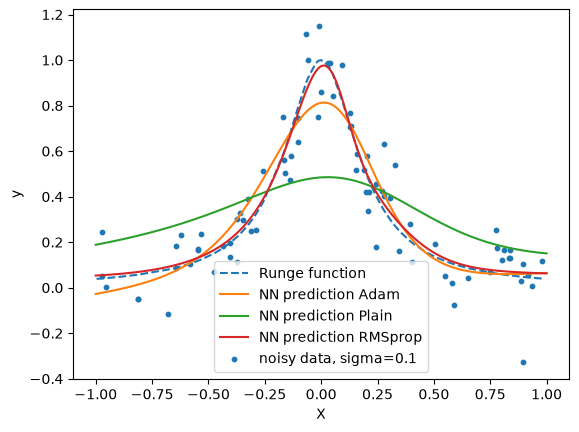

In [3]:
y_pred_adam = feed_forward(X_test, layers_adam, [sigmoid, lambda z: z])
y_pred_plain = feed_forward(X_test, layers_plain, [sigmoid, lambda z: z])
y_pred_RMSprop = feed_forward(X_test, layers_RMSprop, [sigmoid, lambda z: z])

y_pred_unscaled_plain = y_pred_plain.flatten()*ytrain.std()+ytrain.mean()
y_pred_unscaled_adam = y_pred_adam.flatten()*ytrain.std()+ytrain.mean()
y_pred_unscaled_RMSprop = y_pred_RMSprop.flatten()*ytrain.std()+ytrain.mean()


X_plot = np.linspace(-1.0, 1.0, 500).reshape(-1, 1)
X_plot_scaled = (X_plot - Xtrain.mean(axis=0)) / Xtrain.std(axis=0)

y_adam_plot = feed_forward(
    X_plot_scaled,
    layers_adam,
    [sigmoid, lambda z: z]
).flatten() * ytrain.std() + ytrain.mean()

y_RMSprop_plot = feed_forward(
    X_plot_scaled,
    layers_RMSprop,
    [sigmoid, lambda z: z]
).flatten() * ytrain.std() + ytrain.mean()

y_plain_plot = feed_forward(
    X_plot_scaled,
    layers_plain,
    [sigmoid, lambda z: z]
).flatten() * ytrain.std() + ytrain.mean()


sort_idx = np.argsort(X_test.flatten()) 

plt.plot(X, Yrunge, label="Runge function", linestyle="--")
plt.plot(X_plot, y_adam_plot, label="NN prediction Adam")
plt.plot(X_plot, y_plain_plot, label="NN prediction Plain")
plt.plot(X_plot, y_RMSprop_plot, label="NN prediction RMSprop")
plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()


In [ ]:
MSE_plain = np.mean((y_pred_unscaled_plain - ytest)**2)
MSE_adam = np.mean((y_pred_unscaled_adam - ytest)**2)
MSE_RMSprop = np.mean((y_pred_unscaled_RMSprop - ytest)**2)
print(f"MSE for plain SGD: {MSE_plain}")
print(f"MSE for Adam: {MSE_adam}")
print(f"MSE for RMSprop: {MSE_RMSprop}")

In [ ]:
cost_grad = jax.grad(cost, argnums=0)

layers = create_layers(1,[50, 1])

layer_grads = backpropagation(Xtrain, layers, [sigmoid, lambda z: z], target = ytrain.reshape(-1,1), activation_ders = [sigmoid_der, lambda z: np.ones_like(z)])

layer_grads_jax = cost_grad(layers, Xtrain, [sigmoid, lambda z: z], ytrain.reshape(-1, 1))
#print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

Finding good architecture

In [34]:
#c
#ikke kjør på nytt. tar lang tid.
functions = [ReLU, leaky_ReLU, sigmoid]
functions_der = [ReLU_der, leaky_ReLU_der, sigmoid_der]
number_of_nodes = [25,50]
number_of_hidden_layers = np.arange(1, 3)

layer_input_size = 1

epochs = 100
t0 = 1.0
t1 = 100.0
batch_size = 10

MSEs = np.zeros((len(functions), len(number_of_hidden_layers), len(number_of_nodes)))  # Initialize MSE array for all functions
STDs = np.zeros((len(functions), len(number_of_hidden_layers), len(number_of_nodes)))  # Initialize STD array for all functions

for k, (function, function_der) in enumerate(zip(functions, functions_der)):
    for i, n_layers in enumerate(number_of_hidden_layers):
        for j, n_nodes in enumerate(number_of_nodes):
            layer_output_sizes = [n_nodes]*n_layers+[1] #<- ChatGPT la til fix
            #Skrevet av UiOGPT----------------------
            net = make_pipeline(
                StandardScaler(),
                NeuralNetRegressor(
                    input=layer_input_size,
                    hidden_layers=layer_output_sizes,
                    epochs=epochs,
                    batch_size=batch_size,
                    use_decaying_step_length=True,
                    t0=t0,
                    t1=t1,
                    activation=function,
                    activation_der=function_der
                )
            )

            cv = KFold(n_splits=5, shuffle=True, random_state=42)

            fold_mses = []

            for train_idx, val_idx in cv.split(Xtrain):
                X_train_cv = (Xtrain-Xtrain[train_idx].mean(axis=0)) / Xtrain[train_idx].std(axis=0)
                y_train_cv = (ytrain-ytrain[train_idx].mean()) / ytrain[train_idx].std()
                fold_model = clone(net)

                fold_model.fit(
                    X_train_cv[train_idx],
                    y_train_cv[train_idx].reshape(-1, 1)
                )

                y_pred_scaled = fold_model.predict(X_train_cv[val_idx])
                y_pred = y_pred_scaled*ytrain[train_idx].std()+ytrain[train_idx].mean()
                fold_mse = mean_squared_error(
                    ytrain[val_idx],
                    y_pred
                )

                fold_mses.append(fold_mse)
            MSEs[k, i, j] = np.mean(fold_mses)
            STDs[k, i, j] = np.std(fold_mses)
            #----------------------

            


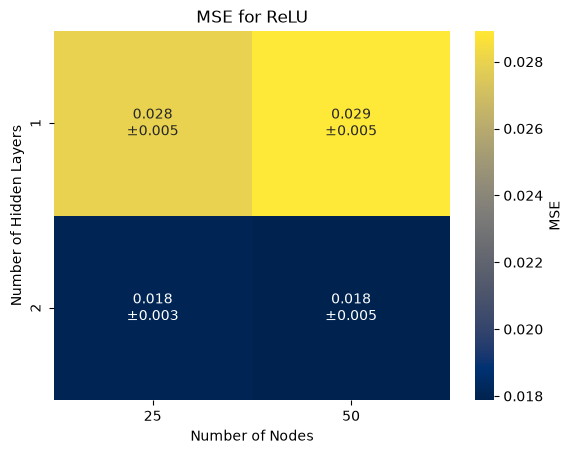

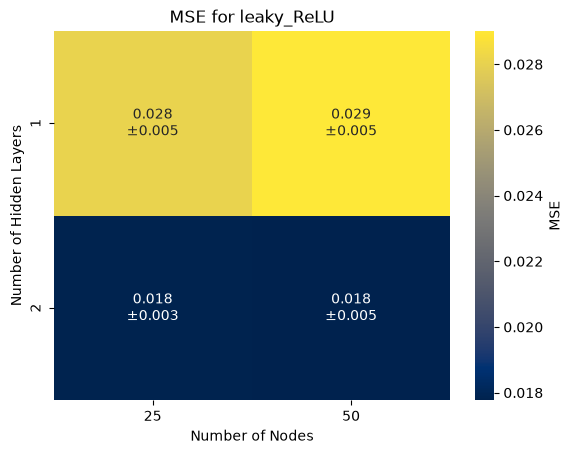

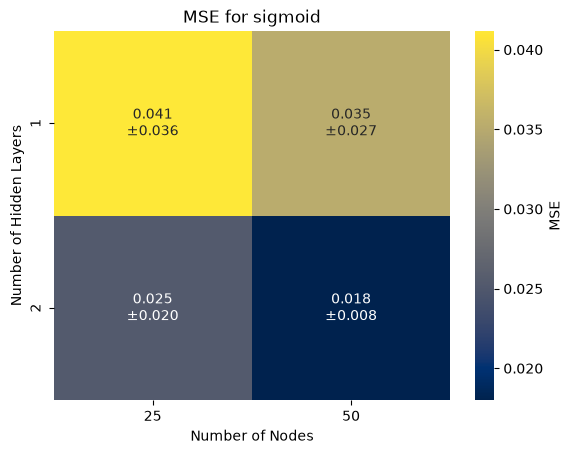

In [35]:
for i in range(len(functions)):
    means = MSEs[i]
    stds = STDs[i]*1.96 #95% confidence interval
    annotations = np.array([[f"{mean:.3f}\n±{std:.3f}" for mean, std in zip(row_mean, row_std)] for row_mean, row_std in zip(means, stds)])
    sns.heatmap(MSEs[i], annot=annotations, fmt="", xticklabels=number_of_nodes, yticklabels=number_of_hidden_layers, cmap = "cividis", cbar_kws={'label': 'MSE'})
    plt.title(f"MSE for {functions[i].__name__}")
    plt.xlabel("Number of Nodes")
    plt.ylabel("Number of Hidden Layers")
    plt.show()

In [36]:
best_model_index = np.unravel_index(np.argmin(MSEs), MSEs.shape)
best_function_idx = best_model_index[0]
best_n_layers = number_of_hidden_layers[best_model_index[1]]
best_nodes = number_of_nodes[best_model_index[2]]

layer_output_sizes = [best_nodes]*best_n_layers+[1]

net = make_pipeline(
    StandardScaler(),
    NeuralNetRegressor(
        input=layer_input_size,
        hidden_layers=layer_output_sizes,
        epochs=epochs,
        batch_size=batch_size,
        use_decaying_step_length=True,
        t0=t0,
        t1=t1,
        activation=functions[best_function_idx],
        activation_der=functions_der[best_function_idx]
    )
)
net.fit(Xtrain, ytrain.reshape(-1, 1))

Best_MSE = mean_squared_error(ytest, net.predict(Xtest))
print(f"Best model: {functions[best_function_idx].__name__} with {best_n_layers} hidden layers and {best_nodes} nodes, MSE on test set: {Best_MSE:.4f}")

Best model: leaky_ReLU with 2 hidden layers and 50 nodes, MSE on test set: 0.0121


In [8]:

input_size = 1
layer_output_sizes = [50, 50, 1]
layers = create_layers(input_size, layer_output_sizes)
activation_functions = [leaky_ReLU, leaky_ReLU, lambda z: z]
activation_ders = [leaky_ReLU_der, leaky_ReLU_der, lambda z: np.ones_like(z)]

layers = train_sgd_adam(
    X_train,
    y_train.reshape(-1,1),
    layers,
    activation_functions,
    activation_ders,
    1000,
    10,
    0.01,
    method = "Ridge",
    lbd = 0.1
)

y_pred = feed_forward(X_test, layers, activation_functions)
y_pred_unscaled = y_pred*ytrain.std()+ytrain.mean()

MSE_test = np.mean((y_pred_unscaled.flatten()- ytest)**2)
print(MSE_test)

sort_idx = np.argsort(Xtest.flatten()) 

plt.plot(X, Yrunge, label="Runge function", linestyle="--")
#plt.plot(Xtest[sort_idx], y_pred_adam[sort_idx], label="NN prediction Adam")
plt.plot(Xtest[sort_idx], y_pred_unscaled[sort_idx], label="NN prediction Plain")
plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()


KeyboardInterrupt: 

In [30]:
#d
layer_output_sizes = [50, 1]  # Example layer sizes for the network
layer_input_size = 1  # Input size for the network

lbds = np.exp(np.linspace(np.log(0.00001), np.log(0.5), 4))
t0s = np.logspace(-1, 1, 3)

epochs = 100
t1 = 100.0
batch_size = 10

methods = ["Lasso", "Ridge", "Plain"]

MSEs = np.zeros((len(methods), len(lbds), len(t0s)))  
STDs = np.zeros((len(methods), len(lbds), len(t0s)))  

for k, method in enumerate(methods):
    for i, lbd in enumerate(lbds):
        for j, t0 in enumerate(t0s):
            #Skrevet av UiOGPT----------------------
            net = make_pipeline(
                StandardScaler(),
                NeuralNetRegressor(
                    input=layer_input_size,
                    hidden_layers=layer_output_sizes,
                    epochs=epochs,
                    batch_size=batch_size,
                    lmbd=lbd,
                    use_decaying_step_length=True,
                    t0=t0,
                    t1=t1,
                    method=method
                )
            )

            cv = KFold(n_splits=5, shuffle=True, random_state=42)

            fold_mses = []

            for train_idx, val_idx in cv.split(Xtrain):
                fold_model = clone(net)
                X_train_cv = (Xtrain-Xtrain[train_idx].mean(axis=0)) / Xtrain[train_idx].std(axis=0)
                y_train_cv = (ytrain-ytrain[train_idx].mean()) / ytrain[train_idx].std()

                fold_model.fit(
                    X_train_cv[train_idx],
                    y_train_cv[train_idx].reshape(-1, 1)
                )

                y_pred_scaled = fold_model.predict(X_train_cv[val_idx])
                y_pred = y_pred_scaled*ytrain[train_idx].std()+ytrain[train_idx].mean()

                fold_mse = mean_squared_error(
                    ytrain[val_idx],
                    y_pred
                )

                fold_mses.append(fold_mse)
            MSEs[k, i, j] = np.mean(fold_mses)
            STDs[k, i, j] = np.std(fold_mses)
            #----------------------
            

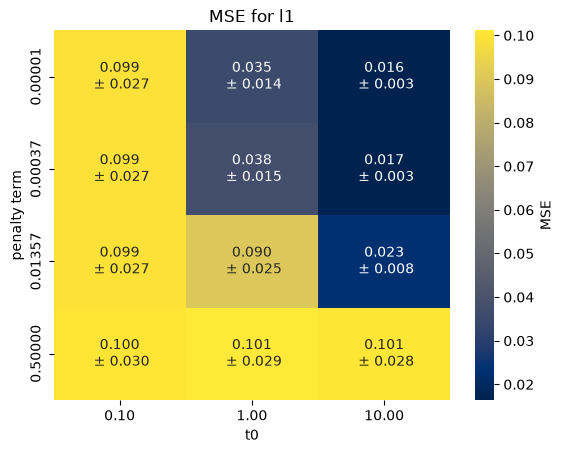

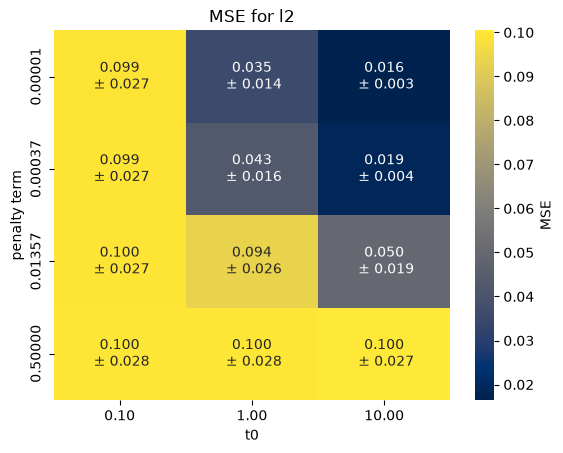

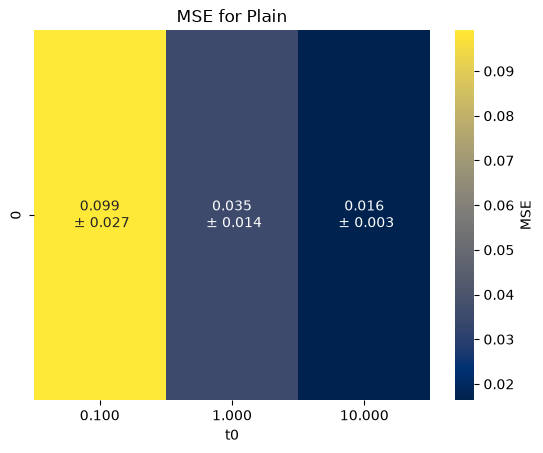

In [31]:
for i, name in enumerate(["l1","l2"]):
    means = MSEs[i]
    stds = STDs[i]

    annotations = np.array([[f"{mean:.3f}\n ± {std:.3f}" for mean, std in zip(mean_row, std_row)] for mean_row, std_row in zip(means, stds)]) #<-UiOGPT la til denne linjen
    sns.heatmap(MSEs[i], annot=annotations, fmt="", xticklabels=[f"{t0:.2f}" for t0 in t0s], yticklabels=[f"{lbd:.5f}" for lbd in lbds], cmap = "cividis", cbar_kws={'label': 'MSE'})#<-ChatGPT hjalp med å legge til labels på plottet
    plt.title(f"MSE for "+name)
    plt.xlabel("t0")
    plt.ylabel("penalty term")
    plt.show()

#For Plain, I pick the 
means = MSEs[2]
stds = STDs[2]
annotations = np.array([[f"{mean:.3f}\n ± {std:.3f}" for mean, std in zip(means[0], stds[0])]]) #<-UiOGPT la til denne linjen
sns.heatmap(MSEs[2,0:1,:], annot=annotations, fmt="", xticklabels=[f"{t0:.3f}" for t0 in t0s], cmap = "cividis", cbar_kws={'label': 'MSE'})#<-ChatGPT hjalp med å legge til labels på plottet
plt.title(f"MSE for Plain")
plt.xlabel("t0")
plt.show()


In [33]:
best_model_index = np.unravel_index(np.argmin(MSEs), MSEs.shape)
best_method = methods[best_model_index[0]]
best_lbd = lbds[best_model_index[1]]
best_t0 = t0s[best_model_index[2]]

net = make_pipeline(
    StandardScaler(),
    NeuralNetRegressor(
        input=layer_input_size,
        hidden_layers=layer_output_sizes,
        epochs=epochs,
        batch_size=batch_size,
        lmbd=best_lbd,
        use_decaying_step_length=True,
        t0=best_t0,
        t1=t1,
        method=best_method
    )
)
net.fit(Xtrain, ytrain)

Best_MSE = mean_squared_error(ytest, net.predict(Xtest))
if best_method == "Plain":
    print(f"Best model: {best_method} with t0={best_t0:.3f}, MSE on test set: {Best_MSE:.4f}")
else:
    print(f"Best model: {best_method} with lbd={best_lbd:.5f} and t0={best_t0:.3f}, MSE on test set: {Best_MSE:.4f}") 

Best model: Plain with t0=10.000, MSE on test set: 0.0133


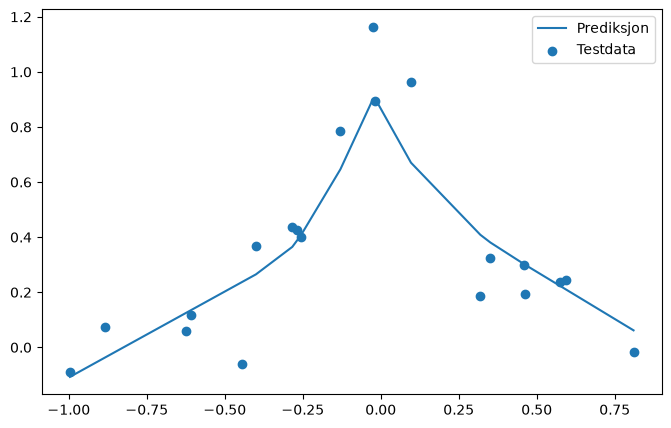

layers:  1  number:  0 mse: 0.018473647491386393
layers:  1  number:  1 mse: 0.01829308603584479
layers:  1  number:  2 mse: 0.01829308603584479
layers:  1  number:  3 mse: 0.01829308603584479
layers:  1  number:  4 mse: 0.01829308603584479
layers:  1  number:  5 mse: 0.01829308603584479
layers:  1  number:  6 mse: 0.01829308603584479
layers:  1  number:  7 mse: 0.01829308603584479
layers:  1  number:  8 mse: 0.01829308603584479


KeyboardInterrupt: 

In [22]:
n_bootstraps = 30
input_size = 1
nodes_per_layer = 30
epochs = 100
batch_size = 10

from sklearn.utils import resample

max_hidden_layers = 4
error = np.zeros(max_hidden_layers)
bias = np.zeros(max_hidden_layers)
variance = np.zeros(max_hidden_layers)

for n_hidden_layers in range(1, max_hidden_layers+1):
    #Making the model
    layer_output_sizes = [nodes_per_layer]*n_hidden_layers + [1]
    activation_functions = [leaky_ReLU]*(n_hidden_layers) + [lambda z: z]  # Last layer is linear
    activation_ders = [leaky_ReLU_der]*(n_hidden_layers) + [lambda z: np.ones_like(z)]  # Last layer is linear

    #Making bootstrapped predictions from samples of the traning set.
    y_pred = np.empty((len(y_test), n_bootstraps))
    for i in range(n_bootstraps):
        x_, y_ = resample(Xtrain, ytrain)
        net = make_pipeline(
            StandardScaler(),
            NeuralNetRegressor(
                input=input_size,
                hidden_layers=layer_output_sizes,
                epochs=epochs,
                batch_size=batch_size,
                use_decaying_step_length=True,
                t0=1.0,
                t1=100.0,
                activation=leaky_ReLU,
                activation_der=leaky_ReLU_der
            )
        )
        net.fit(x_, y_.reshape(-1, 1))
        y_pred[:, i] = net.predict(Xtest).squeeze()
        if i == 0 and n_hidden_layers == 1:
            x_plot = np.asarray(Xtest).ravel()
            y_plot = np.asarray(y_pred[:, 0]).ravel()
            y_true = np.asarray(ytest).ravel()

            idx = np.argsort(x_plot)

            plt.figure(figsize=(8, 5))
            plt.plot(x_plot[idx], y_plot[idx], label="Prediksjon")
            plt.scatter(x_plot, y_true, label="Testdata")

            plt.legend()
            plt.show()
        print("layers: ", n_hidden_layers, " number: ", i, "mse:", np.mean((ytest - y_pred[:, i])**2))

    #Add the error, bias and variance
    error[n_hidden_layers-1] = np.mean(np.mean((ytest[:, None]-y_pred)**2, axis = 1))#<- ChatGPT fikset indekserings feil
    bias[n_hidden_layers-1] = np.mean((ytest - np.mean(y_pred, axis = 1))**2)#<- ChatGPT fikset indekseringsfeil her.
    variance[n_hidden_layers-1] = np.mean(np.var(y_pred, axis = 1))
    



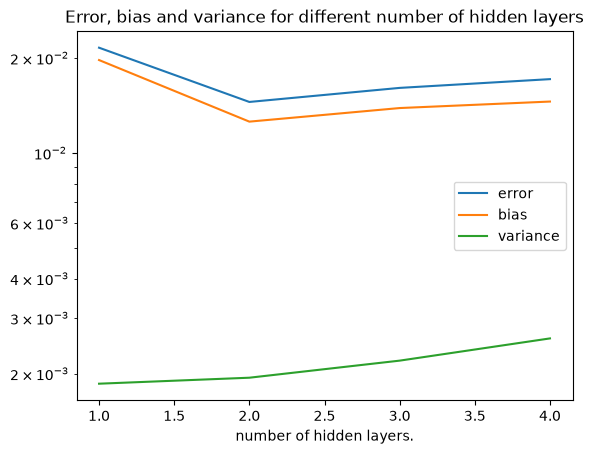

In [6]:
#plot the error, bias and variance
x_axis = np.arange(max_hidden_layers)+1
plt.yscale("log")
plt.plot(x_axis, error)
plt.plot(x_axis, bias)
plt.plot(x_axis, variance)
plt.xlabel("number of hidden layers.")
plt.title("Error, bias and variance for different number of hidden layers")
plt.legend(["error","bias", "variance"])